## Generar visualizaciones sobre el mismo dataset utilizando t-SNE y UMAP, y comparar los grupos identificados en el punto 1.c.


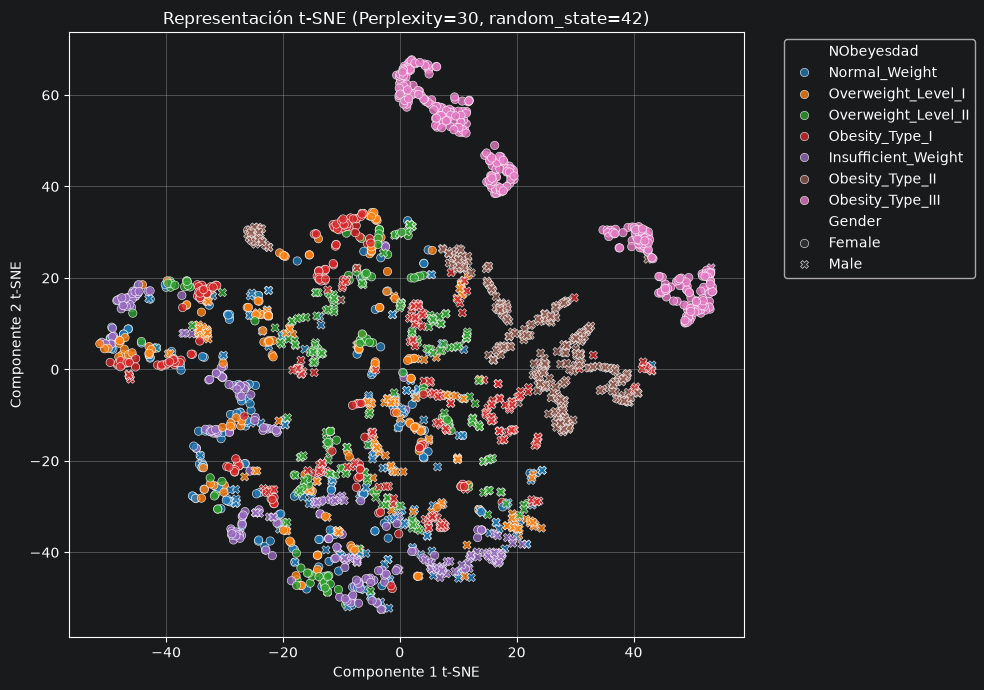

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# 1. Cargar y estandarizar datos cuantitativos
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
num_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

X_scaled = StandardScaler().fit_transform(df[num_cols])

# 2. Aplicar t-SNE con perplejidad 30 y semilla fija
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# 3. Asignar proyecciones al DataFrame
df['tsne_1'] = X_tsne[:, 0]
df['tsne_2'] = X_tsne[:, 1]

# 4. Graficar t-SNE coloreado por NObeyesdad
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='tsne_1',
    y='tsne_2',
    hue='NObeyesdad',
    style='Gender',
    data=df,
    palette='tab10',
    alpha=0.8
)

plt.title('Representación t-SNE (Perplexity=30, random_state=42)')
plt.xlabel('Componente 1 t-SNE')
plt.ylabel('Componente 2 t-SNE')
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

* **Obesity\_Type\_III** **(Obesidad Tipo III):** Forma un cúmulo/isla claramente segregado e aislado en el sector superior e hiper-derecho del gráfico. Al cruzar con la variable `Gender`, se observa que este grupo está integrado casi en un **100% por mujeres (** **Female** **)**, lo que genera una firma no lineal muy marcada en el espacio de características[2].
* **Obesity\_Type\_II** **(Obesidad Tipo II):** Se separa en un bloque diferenciado hacia la zona media-derecha, constituido predominantemente por **hombres (** **Male** **)**[2].
* **Insufficient\_Weight** **(Peso Insuficiente):** Tiende a agruparse en los márgenes inferiores e izquierdos, mostrando una separación nítida respecto a los niveles de obesidad.

**Normal\_Weight** **,** **Overweight\_Level\_I** **,** **Overweight\_Level\_II** **y** **Obesity\_Type\_I** **:** Muestran una región de **transición continua y bastante solapada** en la zona central e izquierda del espacio proyectado[2]. Aunque se intuye un gradiente, las fronteras entre estas categorías intermedias no son disjuntas